In [4]:
import pandas as pd
import numpy as np
import os
import ntpath
import matplotlib.pyplot as plt
from tensorflow import keras
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Convolution2D , MaxPool2D, Dropout, Flatten, Dense,Conv2D
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
from imgaug import augmenters as iaa
import cv2
import ntpath
import random

In [9]:
data = "C:/Users/sarva/Desktop/All projects/Self_Driving_Car/Data/track/driving_log.csv"
column = [ 'center' , 'left', 'right','steering','throttle', 'reverse', 'speed']


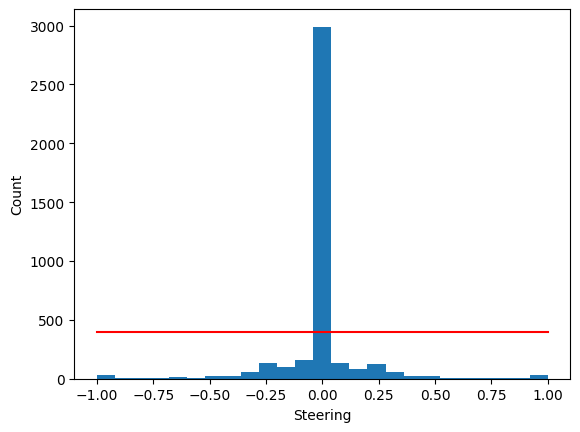

In [25]:
num_bins = 25
samples_per_bin = 400
hist, bins = np.histogram(data['steering'], num_bins)
center = (bins[:-1] + bins[1:]) / 2
plt.bar(center, hist, width=bins[1] - bins[0])
plt.plot(
    [data['steering'].min(), data['steering'].max()],
    [samples_per_bin, samples_per_bin],
    color='red'
)
plt.xlabel('Steering')
plt.ylabel('Count')
plt.show()


In [ ]:


def path_Crop(path):
    head, tail = ntpath.split(path)
    return tail

data['center'] = data['center'].apply(path_Crop)
data['left'] = data['left'].apply(path_Crop)
data['right'] = data['right'].apply(path_Crop)

data.head()

,center,left,right,steering,throttle,reverse,speed
0,center_2018_07_16_17_11_43_382.jpg,left_2018_07_16_17_11_43_382.jpg,right_2018_07_16_17_11_43_382.jpg,0.0,0.0,0.0,0.649786
1,center_2018_07_16_17_11_43_670.jpg,left_2018_07_16_17_11_43_670.jpg,right_2018_07_16_17_11_43_670.jpg,0.0,0.0,0.0,0.627942
2,center_2018_07_16_17_11_43_724.jpg,left_2018_07_16_17_11_43_724.jpg,right_2018_07_16_17_11_43_724.jpg,0.0,0.0,0.0,0.622910
3,center_2018_07_16_17_11_43_792.jpg,left_2018_07_16_17_11_43_792.jpg,right_2018_07_16_17_11_43_792.jpg,0.0,0.0,0.0,0.619162
4,center_2018_07_16_17_11_43_860.jpg,left_2018_07_16_17_11_43_860.jpg,right_2018_07_16_17_11_43_860.jpg,0.0,0.0,0.0,0.615438


In [29]:
remove_list =[]
for j in range(num_bins):
    list_  = []
    for i in range(len(data['steering'])):
        if(data['steering'][i] >= bins[j] and data['steering'][i]<= bins[j+1]):
            list_.append(i)
    list_ = shuffle(list_)
    list_ =list_[samples_per_bin:]
    remove_list.extend(list_)
print ('remove ' , len(remove_list))
data.drop(data.index[remove_list], inplace = True)
print ('remain ' , len(data))

remove  2590
remain  1463


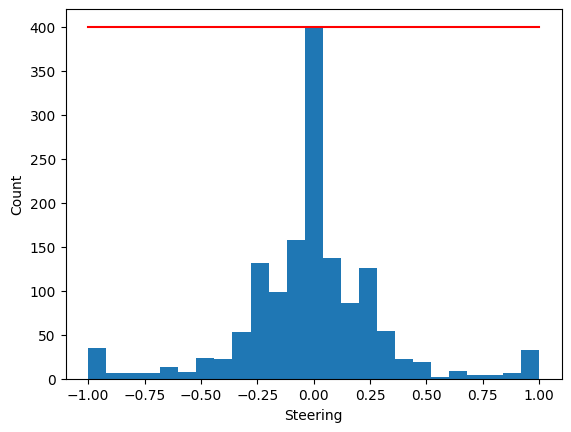

In [30]:
num_bins = 25
samples_per_bin = 400
hist, bins = np.histogram(data['steering'], num_bins)
center = (bins[:-1] + bins[1:]) / 2
plt.bar(center, hist, width=bins[1] - bins[0])
plt.plot(
    [data['steering'].min(), data['steering'].max()],
    [samples_per_bin, samples_per_bin],
    color='red'
)
plt.xlabel('Steering')
plt.ylabel('Count')
plt.show()


In [ ]:
import sys
import tensorflow as tf

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("TensorFlow version:", tf.__version__)
print("Built with CUDA:", tf.test.is_built_with_cuda())

gpus = tf.config.list_physical_devices("GPU")
print("Detected GPUs:", gpus)
print("GPU available:", bool(gpus))

if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
    print("GPU memory growth enabled.")
else:
    print("GPU not detected. Check your TensorFlow installation and environment.")

Python executable: C:\Users\sarva\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe
Python version: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
TensorFlow version: 2.19.1
Built with CUDA: False
Detected GPUs: []
GPU available: False
GPU not detected. Check your TensorFlow installation and environment.
